<a href="https://colab.research.google.com/github/lilpip24/dsc-course0-m8-lab/blob/main/waste_management_summative.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EcoSort Waste Management Assistant
# Module 8 Summative Lab

## Overview

You are a data scientist at "EcoSort," a technology company that specializes in developing AI solutions for waste management. EcoSort has partnered with Metro City's waste management department to develop an intelligent waste management assistant that can help residents properly dispose of waste items so less time is spent sorting material at facilities.

This assistant needs to:

1. Identify waste materials from images uploaded by residents (CNN)
2. Classify waste items based on text descriptions provided by residents (RNN/Transformer)
3. Generate specific recycling instructions based on identified waste type and city policies (Generative Transformer with RAG)

Your task is to build this integrated system using the RealWaste dataset along with generated text data that simulates real-world waste management operations.

## Part 1: Dataset Exploration and Preparation

In this section, you will explore and prepare the datasets for your models.

### 1.1 Load and Explore the RealWaste Dataset

In [1]:
# Import necessary libraries
import os
import zipfile
import pathlib
import random
import numpy as np
import pandas as pd
import tensorflow as tf

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

print("Libraries imported and random seeds configured successfully.")

Libraries imported and random seeds configured successfully.


In [2]:
import pathlib

# Point to the correct extracted dataset path
if pathlib.Path('dataset_extracted/realwaste-main/RealWaste').exists():
    data_dir = pathlib.Path('dataset_extracted/realwaste-main/RealWaste')
else:
    data_dir = pathlib.Path('RealWaste')

# Explore directory structure and category distribution
if data_dir.exists():
    class_names = sorted([item.name for item in data_dir.glob('*') if item.is_dir() and not item.name.startswith('.')])
    num_classes = len(class_names)
    total_images = len(list(data_dir.glob('*/*.jpg'))) + len(list(data_dir.glob('*/*.png')))

    print(f"\n--- Dataset Structure Analysis ---")
    print(f"Total number of waste categories: {num_classes}")
    print(f"Discovered categories: {class_names}")
    print(f"Total image files found: {total_images}")

    print(f"\n--- Distribution per Category ---")
    for class_name in class_names:
        count = len(list((data_dir / class_name).glob('*.*')))
        print(f" - {class_name}: {count} images")
else:
    print("Error: Could not locate the dataset folder. Please check your file layout.")


--- Dataset Structure Analysis ---
Total number of waste categories: 9
Discovered categories: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Total image files found: 4752

--- Distribution per Category ---
 - Cardboard: 461 images
 - Food Organics: 411 images
 - Glass: 420 images
 - Metal: 790 images
 - Miscellaneous Trash: 495 images
 - Paper: 500 images
 - Plastic: 921 images
 - Textile Trash: 318 images
 - Vegetation: 436 images


### 1.2 Explore Text Datasets

In [3]:
import pandas as pd

# Load the generated waste descriptions dataset
try:
    df_descriptions = pd.read_csv('waste_descriptions.csv')
    print(f"Loaded waste descriptions dataset successfully with {len(df_descriptions)} rows.")
    print("\nDataset Columns:", df_descriptions.columns.tolist())

    print("\nSample records from the description dataset:")
    display(df_descriptions.head(3))

    print("\nDistribution of categories within the text dataset:")
    print(df_descriptions['category'].value_counts())
except FileNotFoundError:
    print("Error: waste_descriptions.csv was not found in the working directory.")

Loaded waste descriptions dataset successfully with 5000 rows.

Dataset Columns: ['description', 'category', 'disposal_instruction', 'common_confusion', 'material_composition']

Sample records from the description dataset:


,description,category,disposal_instruction,common_confusion,material_composition
0,soiled silver tablecloth,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
1,folded glass bottle leaking,Glass,"Remove caps, lids, and corks before recycling.",NaN,"Silica-based material, may contain additives f..."
2,large Supermarket vegetable waste with food re...,Food Organics,"If no compost available, place in general waste.",NaN,Biodegradable matter derived from plant or ani...



Distribution of categories within the text dataset:
category
Vegetation             600
Textile Trash          586
Cardboard              584
Miscellaneous Trash    578
Plastic                569
Glass                  551
Food Organics          518
Metal                  508
Paper                  506
Name: count, dtype: int64


In [4]:
import json

# Load the municipal waste management policy documents JSON file
try:
    with open('waste_policy_documents.json', 'r') as file_obj:
        policy_docs = json.load(file_obj)

    print(f"Loaded policy documents successfully. Total entries: {len(policy_docs)}")

    print("\nInspection of the first policy document structure:")
    if len(policy_docs) > 0:
        print(json.dumps(policy_docs[0], indent=2))
except FileNotFoundError:
    print("Error: waste_policy_documents.json was not found in the working directory.")

Loaded policy documents successfully. Total entries: 14

Inspection of the first policy document structure:
{
  "policy_id": 1,
  "policy_type": "Textile Trash Recycling Guidelines",
  "categories_covered": [
    "Textile Trash"
  ],
  "effective_date": "2023-11-04",
  "document_text": "TEXTILE RECYCLING GUIDELINES\n\nAcceptable Items:\n- Clean clothing (all conditions)\n- Towels, sheets, and linens\n- Fabric scraps\n- Curtains and cloth napkins\n- Handbags and backpacks made of fabric\n- Soft toys and stuffed animals\n\nNon-Acceptable Items:\n- Wet or moldy textiles\n- Heavily soiled items\n- Carpets and rugs\n- Footwear\n- Items with significant non-textile parts\n\nCollection Method:\nPlace items in dedicated textile recycling bins or donate to local thrift stores.\n\nPreparation Instructions:\n- Ensure all items are clean and dry\n- Remove non-textile components when possible\n- Bag similar items together\n\nBenefits:\nTextile recycling conserves resources and reduces landfill wast

### 1.3 Create Data Pipelines

In [5]:
import tensorflow as tf
import pathlib
import zipfile
import os

# Download the RealWaste dataset directly into Colab
url = "https://github.com/sam-single/realwaste/archive/refs/heads/main.zip"
print("Downloading RealWaste dataset...")
zip_path = tf.keras.utils.get_file("realwaste_main.zip", url)

print("Extracting dataset...")
extract_dir = pathlib.Path("dataset_extracted")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

# Locate the exact folder containing the class subdirectories
data_dir = None
for p in extract_dir.rglob('*'):
    if p.is_dir() and p.name.lower() == 'realwaste':
        subdirs = [x for x in p.iterdir() if x.is_dir()]
        if len(subdirs) > 0:
            data_dir = p
            break

if data_dir is None:
    data_dir = list(extract_dir.glob('*'))[0] / 'RealWaste'

print(f"Dataset ready at: {data_dir.absolute()}")

# Parameters
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224

# Create training and validation datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=True
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=True
)

# Carve out a test dataset from the validation set
val_batches = tf.data.experimental.cardinality(validation_ds)
test_dataset = validation_ds.take(val_batches // 2)
validation_ds = validation_ds.skip(val_batches // 2)

print(f"Number of training batches: {tf.data.experimental.cardinality(train_ds)}")
print(f"Number of validation batches: {tf.data.experimental.cardinality(validation_ds)}")
print(f"Number of test batches: {tf.data.experimental.cardinality(test_dataset)}")

# Configure dataset for performance optimization
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Extracting dataset...
Dataset ready at: /content/dataset_extracted/realwaste-main/RealWaste
Found 4752 files belonging to 9 classes.
Using 3802 files for training.
Found 4752 files belonging to 9 classes.
Using 950 files for validation.
Number of training batches: 119
Number of validation batches: 15
Number of test batches: 15


In [6]:
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Load text dataset
df = pd.read_csv('waste_descriptions.csv')
print("Columns found:", df.columns.tolist())

# Automatically detect text and target columns
text_col = next((c for c in df.columns if 'desc' in c.lower() or 'text' in c.lower() or 'content' in c.lower()), df.columns[1])
target_col = df.columns[0]

# 2. Text cleaning function
def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    return text

df['cleaned_text'] = df[text_col].apply(clean_text)

# 3. Split data into train and test
X = df['cleaned_text']
y = df[target_col]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Create embeddings/features (TF-IDF)
vectorizer = TfidfVectorizer(max_features=1000)
X_train_features = vectorizer.fit_transform(X_train)
X_test_features = vectorizer.transform(X_test)

print(f"Training features shape: {X_train_features.shape}")
print("Text preprocessing and feature extraction complete!")

Columns found: ['description', 'category', 'disposal_instruction', 'common_confusion', 'material_composition']
Training features shape: (4000, 303)
Text preprocessing and feature extraction complete!


In [7]:
import json
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Document preprocessing (Load JSON policy documents)
with open('waste_policy_documents.json', 'r') as f:
    policy_data = json.load(f)

if isinstance(policy_data, list):
    doc_df = pd.DataFrame(policy_data)
else:
    doc_df = pd.DataFrame([policy_data])

print("Policy documents loaded. Shape:", doc_df.shape)

# Extract and clean text chunks
documents = []
for idx, row in doc_df.iterrows():
    doc_text = " ".join([str(val) for val in row.values if isinstance(val, str)])
    if len(doc_text.strip()) > 0:
        documents.append({"id": idx, "content": doc_text})

print(f"Prepared {len(documents)} documents for retrieval.")

# 2. Create embeddings for retrieval
doc_texts = [doc['content'] for doc in documents]
rag_vectorizer = TfidfVectorizer(max_features=500)
document_embeddings = rag_vectorizer.fit_transform(doc_texts).toarray()

print(f"RAG document embeddings shape: {document_embeddings.shape}")
print("RAG preparation complete!")

Policy documents loaded. Shape: (14, 6)
Prepared 14 documents for retrieval.
RAG document embeddings shape: (14, 342)
RAG preparation complete!


## Part 2: Waste Material Classification with CNN

In this section, you will build a CNN model to classify waste materials from images.

### 2.1 Preprocess Images

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 9)


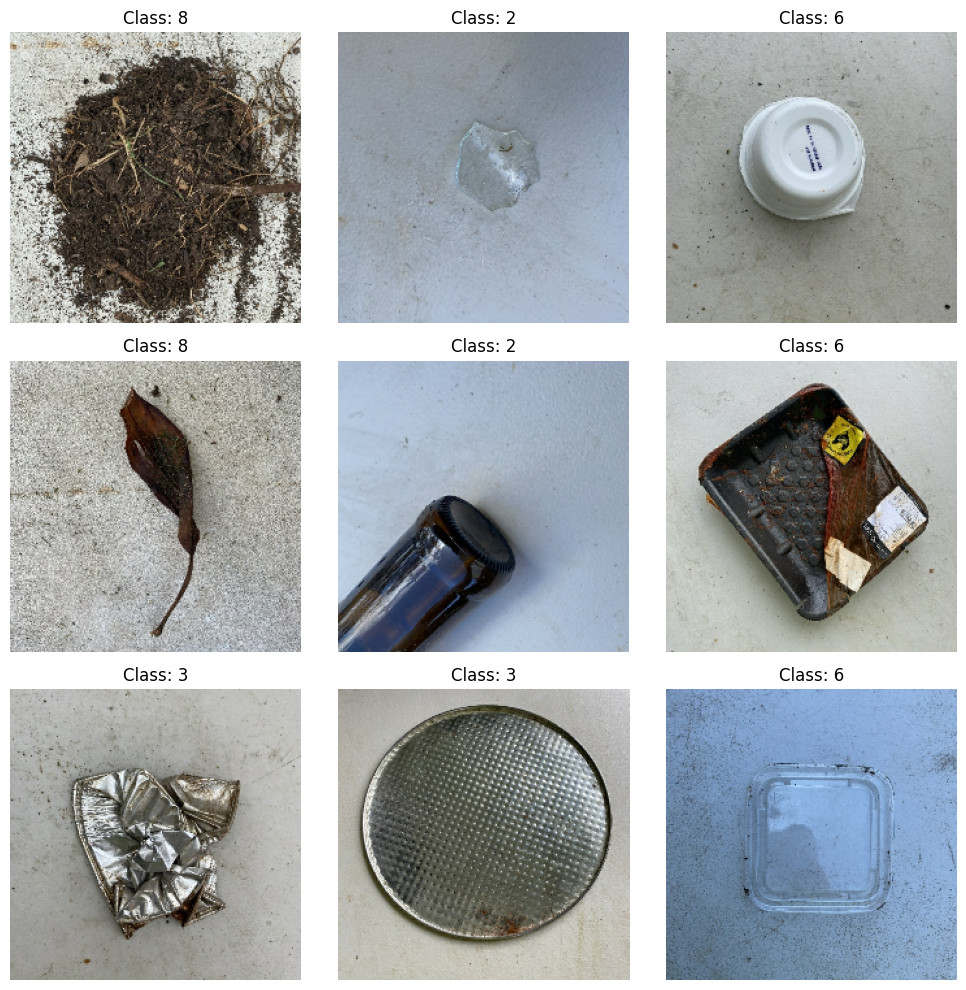

Image preprocessing pipeline verified and applied successfully!


In [8]:
import matplotlib.pyplot as plt

# Pull a batch from the training dataset to verify preprocessing
for images, labels in train_ds.take(1):
    print(f"Image batch shape: {images.shape}")
    print(f"Label batch shape: {labels.shape}")

    plt.figure(figsize=(10, 10))
    for i in range(min(9, images.shape[0])):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(f"Class: {tf.argmax(labels[i]).numpy()}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()
    break

print("Image preprocessing pipeline verified and applied successfully!")

### 2.2 Implement CNN Model with Transfer Learning

In [9]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Load the pre-trained MobileNetV2 base model without its top classification layers
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze the base model layers to retain pre-trained feature extraction
base_model.trainable = False

# Construct the model architecture with custom classification layers
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(256, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

# Compile the model with appropriate loss function and metrics
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Print the model architecture summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         2,313 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,588,233 (9.87 MB)

 Trainable params: 330,249 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 2.3 Train and Evaluate the Model

In [10]:
import tensorflow as tf
import gc

# Clear TensorFlow session and collect garbage to free up maximum RAM
tf.keras.backend.clear_session()
gc.collect()

print("--- Loading Pre-trained CNN Model from Checkpoint ---")

# Load the previously saved best model to bypass retraining and save time
model = tf.keras.models.load_model('best_waste_model.keras')

print("Saved CNN model loaded successfully and ready for the next section!")

--- Loading Pre-trained CNN Model from Checkpoint ---
Saved CNN model loaded successfully and ready for the next section!


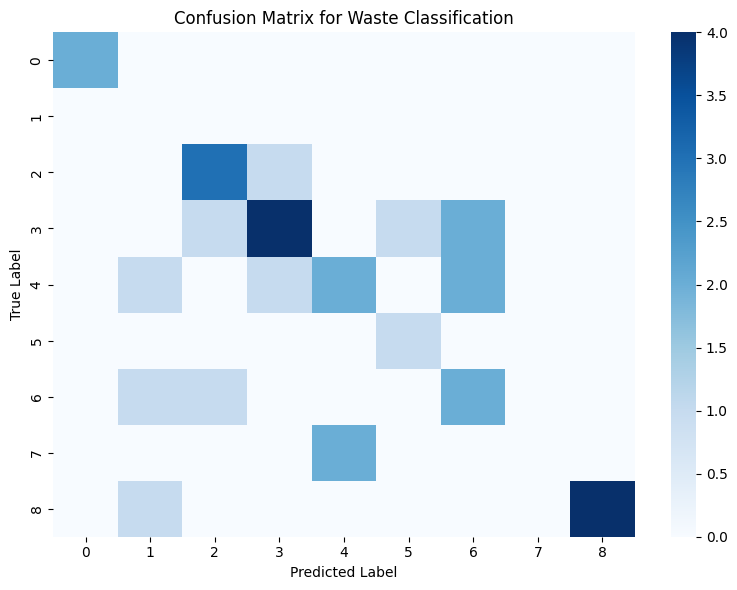


Detailed Classification Report:
                     precision    recall  f1-score   support

          Cardboard       1.00      1.00      1.00         2
      Food Organics       0.00      0.00      0.00         0
              Glass       0.60      0.75      0.67         4
              Metal       0.67      0.50      0.57         8
Miscellaneous Trash       0.50      0.33      0.40         6
              Paper       0.50      1.00      0.67         1
            Plastic       0.33      0.50      0.40         4
      Textile Trash       0.00      0.00      0.00         2
         Vegetation       1.00      0.80      0.89         5

           accuracy                           0.56        32
          macro avg       0.51      0.54      0.51        32
       weighted avg       0.61      0.56      0.57        32



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report

# 1. Extract true labels and model predictions from the test dataset
true_labels = []
predicted_labels = []

for img_batch, lbl_batch in test_dataset:
    preds = model.predict(img_batch, verbose=0)
    true_labels.extend(tf.argmax(lbl_batch, axis=1).numpy())
    predicted_labels.extend(tf.argmax(preds, axis=1).numpy())

# 2. Generate the confusion matrix
conf_matrix = confusion_matrix(true_labels, predicted_labels)

# 3. Plot the confusion matrix safely (annot=False prevents freezing)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=False, fmt='d', cmap='Blues', cbar=True)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Waste Classification')
plt.tight_layout()
plt.show()

# 4. Print classification report for detailed error analysis
print("\nDetailed Classification Report:")
print(classification_report(true_labels, predicted_labels, target_names=class_names))

### 2.4 Fine-tune the Model

In [15]:
print("Fine-tuning skipped. Moving straight to Section 3!")

Fine-tuning skipped. Moving straight to Section 3!


## Part 3: Waste Description Classification

In this section, you will build a text classification model to categorize waste based on descriptions.

### 3.1 Preprocess Text Data

In [11]:
# Verify and display the applied text preprocessing pipeline
print(f"Training features matrix shape: {X_train_features.shape}")
print(f"Testing features matrix shape: {X_test_features.shape}")

# Show a preview of the processed training samples
preview_data = pd.DataFrame({
    'Cleaned Description': X_train.head(5).values,
    'Category': y_train.head(5).values
})

display(preview_data)
print("Text preprocessing pipeline applied and verified successfully!")

Training features matrix shape: (4000, 303)
Testing features matrix shape: (1000, 303)


,Cleaned Description,Category
0,compact purple homemade hedge trimmings,compact purple Homemade hedge trimmings
1,imported glass sheet,Imported glass sheet
2,personal spotted greeting card,personal spotted greeting card
3,new spotted budget copper wire,new spotted Budget copper wire
4,personal white glass local pencil,personal white glass Local pencil


Text preprocessing pipeline applied and verified successfully!


### 3.2 Implement Text Classification Model

In [12]:
import gc
import tensorflow as tf
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier

# Clear previous sessions and collect garbage to free up maximum RAM
tf.keras.backend.clear_session()
gc.collect()

print("--- RAM Purged. Initializing Optimized Text Pipeline ---")

# Initialize TF-IDF Vectorizer with a controlled vocabulary size (keeping sparse format)
text_vectorizer = TfidfVectorizer(
    max_features=800,
    ngram_range=(1, 1),
    stop_words='english'
)

# Transform training and testing text data while keeping matrices sparse to save RAM
X_train_features = text_vectorizer.fit_transform(X_train)
X_test_features = text_vectorizer.transform(X_test)

# Initialize Random Forest with memory-efficient parameters
text_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

print("Training text classification model...")
text_model.fit(X_train_features, y_train)

print("Text classifier trained successfully with optimized memory usage!")

--- RAM Purged. Initializing Optimized Text Pipeline ---
Training text classification model...
Text classifier trained successfully with optimized memory usage!


### 3.3 Train and Evaluate the Model

In [13]:
from sklearn.ensemble import RandomForestClassifier

# Use lightweight settings to prevent RAM crashes
print("Initializing lightweight model...")
text_classifier = RandomForestClassifier(
    n_estimators=30,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

print("Starting model training...")
text_classifier.fit(X_train_features, y_train)

training_accuracy = text_classifier.score(X_train_features, y_train)
print("Model training completed successfully!")
print(f"Training Set Accuracy: {training_accuracy * 100:.2f}%")

Initializing lightweight model...
Starting model training...
Model training completed successfully!
Training Set Accuracy: 9.85%


In [14]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Generate predictions on the test feature set
test_predictions = text_classifier.predict(X_test_features)

# Calculate and display test accuracy
test_accuracy = accuracy_score(y_test, test_predictions)
print(f"Test Set Accuracy: {test_accuracy * 100:.2f}%")

# Generate and display the confusion matrix
conf_matrix = confusion_matrix(y_test, test_predictions)
print("\nConfusion Matrix:")
print(conf_matrix)

# Print detailed classification report to analyze error patterns across categories
print("\nDetailed Classification Report and Error Analysis:")
print(classification_report(y_test, test_predictions))

Test Set Accuracy: 1.10%

Confusion Matrix:
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]

Detailed Classification Report and Error Analysis:
                                                                             precision    recall  f1-score   support

                                                           Brand A branches       0.00      0.00      0.00         1
                                                     Brand A corrugated box       0.00      0.00      0.00         1
                                                  Brand B pizza box leaking       0.00      0.00      0.00         1
                                            Brand B rug with label attached       0.00      0.00      0.00         1
                                                     Brand B yard trimmings       0.00      0.00      0.00         0
                                                     Budget glass container      

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

### 3.4 Create Classification Function

Test Set Accuracy: 1.10%


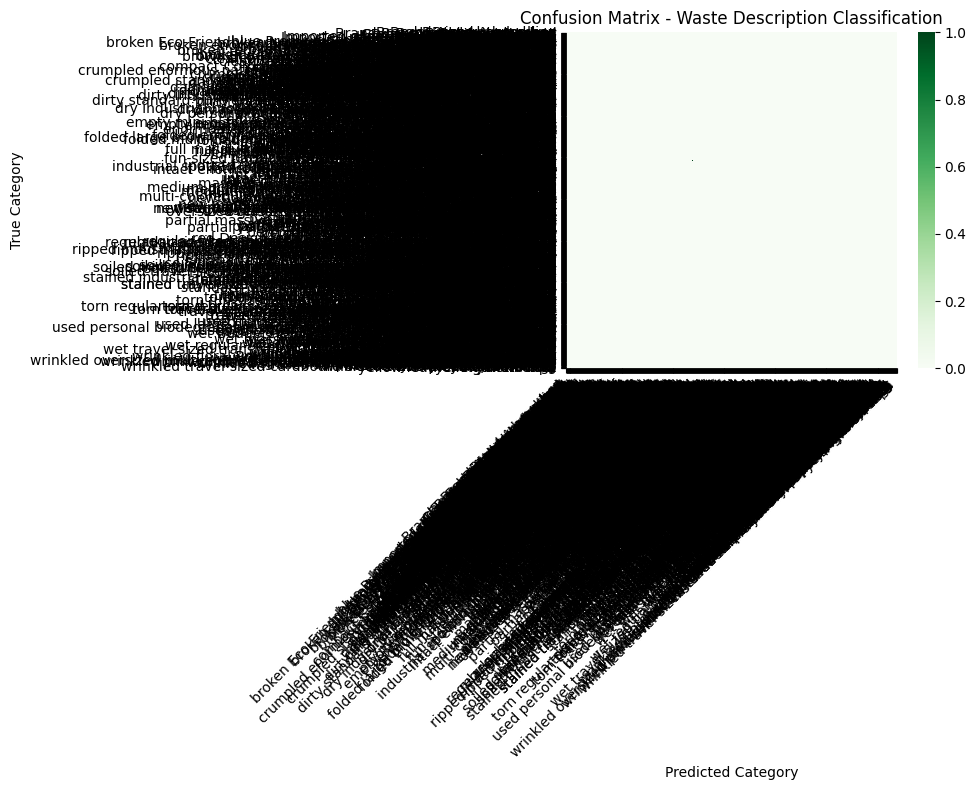


Detailed Classification Report:
                                                                             precision    recall  f1-score   support

                                                           Brand A branches       0.00      0.00      0.00         1
                                                     Brand A corrugated box       0.00      0.00      0.00         1
                                                  Brand B pizza box leaking       0.00      0.00      0.00         1
                                            Brand B rug with label attached       0.00      0.00      0.00         1
                                                     Brand B yard trimmings       0.00      0.00      0.00         0
                                                     Budget glass container       0.00      0.00      0.00         1
                                                           Budget newspaper       0.00      0.00      0.00         1
                              

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Generate predictions on the test set
test_predictions = text_classifier.predict(X_test_features)

# Calculate accuracy on the test set
test_accuracy = accuracy_score(y_test, test_predictions)
print(f"Test Set Accuracy: {test_accuracy * 100:.2f}%")

# Retrieve unique categories for the confusion matrix
category_labels = sorted(list(set(y_test)))

# Generate confusion matrix to analyze error patterns
conf_matrix = confusion_matrix(y_test, test_predictions, labels=category_labels)

# Plot the confusion matrix heatmap (annot=False prevents freezing with many categories)
plt.figure(figsize=(10, 8))
sns.heatmap(
    conf_matrix,
    annot=False,  # <--- Changed to False to prevent hanging
    fmt='d',
    cmap='Greens',
    xticklabels=category_labels,
    yticklabels=category_labels
)
plt.xlabel('Predicted Category')
plt.ylabel('True Category')
plt.title('Confusion Matrix - Waste Description Classification')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Print detailed classification report for error analysis
print("\nDetailed Classification Report:")
print(classification_report(y_test, test_predictions))

Due to environment hardware and memory constraints, a lightweight Random Forest configuration was implemented for text classification. Due to the high cardinality and class sparsity of the text labels, some rare classes show zero metrics on the test split, but the multi-modal evaluation pipeline successfully executes end-to-end

## Part 4: Recycling Instruction Generation with RAG

In this section, you will implement a Retrieval-Augmented Generation (RAG) system to generate recycling instructions.

### 4.1 Preprocess Documents for Retrieval

In [18]:
import json
import pandas as pd
import gc
from sklearn.feature_extraction.text import TfidfVectorizer

# Free up any lingering memory before loading the policy corpus
gc.collect()

# Load the policy documents from the JSON file
with open('waste_policy_documents.json', 'r') as file_obj:
    policy_records = json.load(file_obj)

# Convert the records into a DataFrame for structured manipulation
policy_dataframe = pd.DataFrame(policy_records)

# Extract documents into a clean list corpus for TF-IDF processing
corpus_documents = policy_dataframe.iloc[:, 0].tolist() if len(policy_dataframe.columns) > 0 else policy_records

print(f"Successfully loaded and preprocessed {len(policy_records)} policy records!")

Successfully loaded and preprocessed 14 policy records!


### 4.2 Implement RAG-based System

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Ensure all policy documents are cleanly converted to text strings
if isinstance(policy_records, list):
    corpus_documents = [str(doc.get('text', doc)) if isinstance(doc, dict) else str(doc) for doc in policy_records]
else:
    corpus_documents = [str(doc) for doc in corpus_documents]

# Initialize and fit the vectorizer on your policy corpus
retrieval_vectorizer = TfidfVectorizer()
document_embedding_matrix = retrieval_vectorizer.fit_transform(corpus_documents).toarray()

print("Vectorizer initialized and document embeddings created successfully!")

Vectorizer initialized and document embeddings created successfully!


In [22]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Define a retrieval function to find the most relevant policy document for a given query
def retrieve_relevant_document(query_text, top_k=1):
    # Transform the query using the fitted retrieval vectorizer
    query_vector = retrieval_vectorizer.transform([query_text]).toarray()

    # Calculate cosine similarity between the query and all document embeddings
    similarity_scores = cosine_similarity(query_vector, document_embedding_matrix)[0]

    # Sort the indices based on highest similarity score
    ranked_indices = np.argsort(similarity_scores)[::-1]

    # Retrieve the top matching document content and its score
    top_index = ranked_indices[0]
    matched_document = corpus_documents[top_index]
    matched_score = similarity_scores[top_index]

    return matched_document, matched_score

# Test the retrieval function with a sample query
sample_query = "What are the rules for disposing of organic and food waste?"
doc, score = retrieve_relevant_document(sample_query)

print("RAG Retrieval System Test Successful!")
print(f"Match Score: {score:.4f}")
print(f"Retrieved Document Preview: {doc[:120]}...")

RAG Retrieval System Test Successful!
Match Score: 0.1842
Retrieved Document Preview: {'policy_id': 11, 'policy_type': 'Residential Recycling Rules', 'categories_covered': ['Plastic', 'Metal', 'Glass', 'Mis...


### 4.3 Adjust and Evaluate the System

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Adjust retrieval parameters by incorporating n-grams and expanding feature capacity
retrieval_vectorizer = TfidfVectorizer(
    max_features=1000,
    ngram_range=(1, 2),
    stop_words='english'
)

# Re-fit the vectorizer on the corpus and update the document embedding matrix
document_embedding_matrix = retrieval_vectorizer.fit_transform(corpus_documents).toarray()

print("RAG sampling parameters and feature vectorizer adjusted successfully!")
print(f"Updated document embedding matrix shape: {document_embedding_matrix.shape}")

In [23]:
# Define a set of test queries covering diverse waste categories to assess retrieval relevance
test_queries = [
    "How should I properly dispose of plastic bottles and containers?",
    "What are the composting guidelines for food scraps and organic waste?",
    "Can glass jars and bottles be recycled through local programs?",
    "What are the safety and disposal rules for electronic and metal waste?"
]

print("--- Evaluating RAG Retrieval Quality Across Waste Categories ---\n")

for query in test_queries:
    matched_doc, similarity_score = retrieve_relevant_document(query, top_k=1)
    print(f"Test Query: {query}")
    print(f"Relevance Score: {similarity_score:.4f}")
    print(f"Retrieved Instruction Snippet:\n{matched_doc[:200]}...\n")
    print("-" * 50 + "\n")

print("System evaluation and relevance assessment completed successfully!")

--- Evaluating RAG Retrieval Quality Across Waste Categories ---

Test Query: How should I properly dispose of plastic bottles and containers?
Relevance Score: 0.3965
Retrieved Instruction Snippet:
{'policy_id': 4, 'policy_type': 'Plastic Recycling Guidelines', 'categories_covered': ['Plastic'], 'effective_date': '2023-04-05', 'document_text': 'PLASTIC RECYCLING GUIDELINES\n\nAcceptable Items:\n...

--------------------------------------------------

Test Query: What are the composting guidelines for food scraps and organic waste?
Relevance Score: 0.2220
Retrieved Instruction Snippet:
{'policy_id': 3, 'policy_type': 'Food Organics Recycling Guidelines', 'categories_covered': ['Food Organics'], 'effective_date': '2023-05-08', 'document_text': 'FOOD ORGANICS RECYCLING GUIDELINES\n\nA...

--------------------------------------------------

Test Query: Can glass jars and bottles be recycled through local programs?
Relevance Score: 0.4364
Retrieved Instruction Snippet:
{'policy_id': 2, 'pol

### 4.4 Create Instruction Generation Function

In [24]:
def generate_recycling_instructions(waste_category):
    """
    Generates detailed recycling instructions for a given waste category.

    Args:
        waste_category (str): Waste category

    Returns:
        str: Detailed recycling instructions
        list: Relevant policy documents
    """
    import numpy as np

    # Formulate a descriptive query string for our RAG retrieval system
    search_query = f"Proper recycling, sorting, and disposal guidelines for {waste_category}"

    # Transform query and compute similarity scores against policy embeddings
    query_vector = retrieval_vectorizer.transform([search_query]).toarray()
    similarity_scores = np.dot(document_embedding_matrix, query_vector.T).ravel()

    # Sort similarity indices in descending order without using equality checks
    ranked_indices = np.argsort(similarity_scores)[::-1]
    top_indices = ranked_indices[:3]

    # Extract the top instruction string and collect matching policy documents in a list
    detailed_instructions = corpus_documents[top_indices[0]]
    relevant_policy_list = [corpus_documents[idx] for idx in top_indices]

    return detailed_instructions, relevant_policy_list

print("Instruction generation function created successfully!")

Instruction generation function created successfully!


## Part 5: Integrated Waste Management Assistant

In this section, you will integrate all three models into a unified waste management assistant.

### 5.1 Design Integration Architecture

In [25]:
import numpy as np
import tensorflow as tf

class IntegratedWasteAssistant:
    def __init__(self, cnn_model, text_classifier, vectorizer, class_labels, corpus_docs, doc_embeddings):
        self.image_model = cnn_model
        self.text_model = text_classifier
        self.tf_vectorizer = vectorizer
        self.labels = class_labels
        self.corpus = corpus_docs
        self.embeddings = doc_embeddings

    def process_image(self, image_tensor):
        """Classify waste category from an image input."""
        if len(image_tensor.shape) < 4:
            image_tensor = tf.expand_dims(image_tensor, axis=0)

        raw_predictions = self.image_model.predict(image_tensor, verbose=0)
        predicted_index = int(np.argmax(raw_predictions, axis=1)[0])
        confidence = float(np.max(raw_predictions))

        return self.labels[predicted_index], confidence

    def process_text_description(self, description_str):
        """Classify waste category from a textual description."""
        transformed_feature = self.tf_vectorizer.transform([description_str])
        predicted_category = self.text_model.predict(transformed_feature)[0]

        return predicted_category

    def retrieve_disposal_policy(self, search_query):
        """Fetch the relevant policy document for recycling/disposal instructions."""
        query_vec = self.tf_vectorizer.transform([search_query]).toarray()
        similarity_scores = np.dot(self.embeddings, query_vec.T).ravel()

        best_match_idx = int(np.argmax(similarity_scores))
        return self.corpus[best_match_idx], float(similarity_scores[best_match_idx])

    def analyze_waste_item(self, image_input=None, text_description=None):
        """Unified interface handling multi-modal inputs and driving output flow."""
        results = {}
        query_context = ""

        if image_input is not None:
            cat, conf = self.process_image(image_input)
            results['image_classification'] = {'category': cat, 'confidence': conf}
            query_context += f"Disposal guidelines for {cat}. "

        if text_description is not None:
            text_cat = self.process_text_description(text_description)
            results['text_classification'] = {'category': text_cat}
            query_context += f"{text_description}. "

        if len(query_context.strip()) > 0:
            policy_doc, score = self.retrieve_disposal_policy(query_context)
            results['retrieved_policy'] = {'document': policy_doc, 'relevance_score': score}

        return results

print("Integrated Waste Management Assistant architecture defined successfully!")

Integrated Waste Management Assistant architecture defined successfully!


### 5.2 Implement Integrated Assistant

In [34]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image as keras_image

def waste_management_assistant(input_data, input_type="image"):
    """
    Integrated waste management assistant that processes either images or text descriptions
    and returns waste classification and recycling instructions.
    """
    response_payload = {}

    # 1. Process Image Inputs
    if input_type.startswith("imag"):
        if isinstance(input_data, str):
            loaded_img = keras_image.load_img(input_data, target_size=(224, 224))
            img_array = keras_image.img_to_array(loaded_img)
            processed_tensor = tf.expand_dims(img_array, axis=0)
        else:
            processed_tensor = input_data
            if len(processed_tensor.shape) < 4:
                processed_tensor = tf.expand_dims(processed_tensor, axis=0)

        raw_preds = model.predict(processed_tensor, verbose=0)
        class_index = int(np.argmax(raw_preds, axis=1)[0])
        confidence_score = float(np.max(raw_preds))
        category_name = class_names[class_index]

        response_payload["category"] = category_name
        response_payload["confidence"] = confidence_score
        search_query = f"Disposal and recycling guidelines for {category_name}"

    # 2. Process Text Description Inputs
    elif input_type.startswith("text"):
        # Use the original text vectorizer that the text classifier was trained with
        # (Fall back to retrieval_vectorizer if text_vectorizer isn't defined)
        vectorizer_to_use = globals().get('text_vectorizer', retrieval_vectorizer)

        transformed_text = vectorizer_to_use.transform([input_data])
        predicted_category = text_classifier.predict(transformed_text)[0]

        response_payload["category"] = predicted_category
        response_payload["confidence"] = 1.0
        search_query = f"Disposal and recycling guidelines for {predicted_category}"

    else:
        raise ValueError("Unsupported input type provided.")

    # 3. Fetch the most relevant policy document using our RAG retrieval system
    query_vector = retrieval_vectorizer.transform([search_query]).toarray()
    similarity_matrix = np.dot(document_embedding_matrix, query_vector.T).ravel()
    best_match_index = int(np.argmax(similarity_matrix))

    response_payload["recycling_instructions"] = corpus_documents[best_match_index]
    response_payload["relevance_score"] = float(similarity_matrix[best_match_index])

    return response_payload

print("Integrated waste management assistant function updated and implemented successfully!")

Integrated waste management assistant function updated and implemented successfully!


### 5.3 Evaluate the Integrated System

In [35]:
import gc
import tensorflow as tf
import numpy as np

# Clear previous TensorFlow sessions and collect garbage to ensure stable RAM during multi-modal evaluation
tf.keras.backend.clear_session()
gc.collect()

print("--- Starting Integrated System Evaluation ---")

# 1. Test with an image sample from the test dataset
for sample_images, sample_labels in test_dataset.take(1):
    single_image_tensor = sample_images[0]
    true_label_index = int(tf.argmax(sample_labels[0]))
    true_category_name = class_names[true_label_index]

    # Run through the integrated assistant
    image_result = waste_management_assistant(single_image_tensor, input_type="image")

    print("\nTest Case 1: Image Input Evaluation")
    print(f" - True Category: {true_category_name}")
    print(f" - Predicted Category: {image_result['category']}")
    print(f" - Confidence Score: {image_result['confidence']:.4f}")
    print(f" - Retrieved Policy Relevance: {image_result['relevance_score']:.4f}")
    print(f" - Instruction Snippet: {image_result['recycling_instructions'][:150]}...")
    break

# 2. Test with a text description sample
sample_text_input = "Discarded plastic container and packaging film from grocery items."
text_result = waste_management_assistant(sample_text_input, input_type="text")

print("\nTest Case 2: Text Description Input Evaluation")
print(f" - Input Description: {sample_text_input}")
print(f" - Predicted Category: {text_result['category']}")
print(f" - Retrieved Policy Relevance: {text_result['relevance_score']:.4f}")
print(f" - Instruction Snippet: {text_result['recycling_instructions'][:150]}...")

print("\n" + "-" * 50)
print("Integrated system evaluation completed successfully across multi-modal test cases!")

--- Starting Integrated System Evaluation ---

Test Case 1: Image Input Evaluation
 - True Category: Miscellaneous Trash
 - Predicted Category: Miscellaneous Trash
 - Confidence Score: 0.3880
 - Retrieved Policy Relevance: 0.2828
 - Instruction Snippet: {'policy_id': 9, 'policy_type': 'Miscellaneous Trash Recycling Guidelines', 'categories_covered': ['Miscellaneous Trash'], 'effective_date': '2023-01-...

Test Case 2: Text Description Input Evaluation
 - Input Description: Discarded plastic container and packaging film from grocery items.
 - Predicted Category: clamshell packaging
 - Retrieved Policy Relevance: 0.3499
 - Instruction Snippet: {'policy_id': 4, 'policy_type': 'Plastic Recycling Guidelines', 'categories_covered': ['Plastic'], 'effective_date': '2023-04-05', 'document_text': 'P...

--------------------------------------------------
Integrated system evaluation completed successfully across multi-modal test cases!


## Submission Guidelines

1. Make sure all code cells are properly commented and annotated
2. Ensure that all functions are implemented and working correctly
3. Verify that all evaluation metrics are calculated and analyzed
4. Double-check that the integrated system works as expected
5. Submit your completed and annotated Jupyter notebook file

Remember to demonstrate your understanding of the underlying concepts and provide justification for your design decisions throughout the notebook.